# 04 — Optimised ResNet-50 (round 2): resolution, test-time augmentation, epochs, augmentation

Starting point: plain-CE ResNet-50 + logit adjustment (notebook 03, 0.786 test). Each variant changes **one factor**,
runs on all 5 folds with the same seed, and is then re-evaluated with test-time augmentation (TTA) and logit-adjusted:

| Factor | Variant | Flag |
|---|---|---|
| Input resolution | 384 px, 448 px (same field of view: resize = size × 256/224) | `--img-size 384 / 448` |
| Training length | 60 epochs | `--epochs 60` |
| Augmentation | TrivialAugmentWide instead of mild color jitter | `--augment trivial` |
| Test-time augmentation | 4 views (flips) or 20 views (5 crops × flips) | `evaluate_tta.py --crops 1 / 5` |

**Selection rule:** the configuration with the best mean **CV** balanced accuracy wins; test numbers are reported for every
variant but never used to choose.

**Reproduce (~75 min on one node):** `salloc ... srun ... bash slurm/run_round2_node.sh`

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Results below are loaded from results/. Set RUN_TRAINING = True (on a GPU node) to re-create
# one fold of this version first; the full 5-fold runs use the slurm/ drivers listed above.
RUN_TRAINING = False

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

In [2]:
if RUN_TRAINING:   # the selected configuration, one fold (~16 min on an A100)
    run("python train_classifier.py --run-name resnet50_ce_res448 --img-size 448 --fold 0")
    run("python evaluate_tta.py resnet50_ce_res448 --crops 5 --folds 0")
    run("python posthoc_logit_adjustment.py resnet50_ce_res448_tta20")

## 1. Every variant, ranked by CV balanced accuracy

In [3]:
rows = []
for base, label in [("resnet50_ce", "224 px"), ("resnet50_ce_res384", "384 px"), ("resnet50_ce_res448", "448 px"),
                    ("resnet50_ce_ep60", "224 px, 60 epochs"), ("resnet50_ce_trivial", "224 px, TrivialAugment")]:
    for tta, tl in [("", ""), ("_tta4", " + TTA-4"), ("_tta20", " + TTA-20")]:
        r = f"{base}{tta}_la"
        cv, te = A.per_fold(r, "cv_val"), A.per_fold(r, "official_test")
        rows.append({"variant": label + tl, "tau": A.tau(r)["selected_tau"], "cv_bal_acc": cv.bal_acc.mean(),
                     "cv_std": cv.bal_acc.std(ddof=0), "test_bal_acc": te.bal_acc.mean(), "test_std": te.bal_acc.std(ddof=0),
                     "test_auc": te.auc.mean(), "test_mel_sens": te.mel_sens.mean(),
                     "test_5model_avg": A.fold_ensemble(r)["balanced_acc"]})
table = pd.DataFrame(rows).sort_values("cv_bal_acc", ascending=False).reset_index(drop=True)
table.round(4)

,variant,tau,cv_bal_acc,cv_std,test_bal_acc,test_std,test_auc,test_mel_sens,test_5model_avg
0,448 px + TTA-20,1.6,0.8313,0.0160,0.8346,0.0135,0.9727,0.7591,0.8699
1,448 px + TTA-4,1.7,0.8289,0.0161,0.8373,0.0119,0.9720,0.7789,0.8710
2,448 px,2.0,0.8174,0.0172,0.8261,0.0118,0.9671,0.7696,0.8630
3,384 px + TTA-4,0.9,0.8104,0.0209,0.7984,0.0175,0.9710,0.7731,0.8467
4,384 px + TTA-20,0.8,0.8090,0.0201,0.8045,0.0147,0.9728,0.7661,0.8486
5,"224 px, TrivialAugment + TTA-20",1.6,0.8040,0.0177,0.8107,0.0140,0.9672,0.6713,0.8410
6,224 px + TTA-20,1.1,0.8027,0.0170,0.8042,0.0094,0.9684,0.6947,0.8377
7,"224 px, TrivialAugment + TTA-4",1.4,0.8014,0.0153,0.8011,0.0067,0.9685,0.6713,0.8372
8,384 px,1.2,0.7995,0.0202,0.7897,0.0139,0.9663,0.7614,0.8467
9,224 px + TTA-4,1.1,0.7983,0.0177,0.7950,0.0060,0.9674,0.7006,0.8399


## 2. Where the gain comes from (paired over 5 folds)

In [4]:
steps = [("resnet50_ce_la", "resnet50_ce", "+ logit adjustment"),
         ("resnet50_ce_res448_la", "resnet50_ce_la", "+ 448 px"),
         ("resnet50_ce_res448_tta20_la", "resnet50_ce_res448_la", "+ TTA-20"),
         ("resnet50_ce_res448_tta20_la", "resnet50_ce", "total vs plain baseline"),
         ("resnet50_ce_res384_la", "resnet50_ce_la", "384 px alone"),
         ("resnet50_ce_ep60_la", "resnet50_ce_la", "60 epochs alone"),
         ("resnet50_ce_trivial_la", "resnet50_ce_la", "TrivialAugment alone"),
         ("resnet50_ce_res448_tta20_la", "gessert2018_densenet121", "optimised vs Gessert")]
pd.concat([A.paired_table([a], b, names=[n]) for a, b, n in steps])

,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
+ logit adjustment,+0.028 ± 0.014 (5/5),+0.059 ± 0.042 (5/5),-0.012 ± 0.004 (0/5),+0.063 ± 0.008 (5/5),+0.080 ± 0.019 (5/5),-0.008 ± 0.005 (0/5)
+ 448 px,+0.031 ± 0.004 (5/5),+0.072 ± 0.104 (3/5),+0.010 ± 0.004 (5/5),+0.040 ± 0.014 (5/5),+0.091 ± 0.021 (5/5),+0.009 ± 0.004 (5/5)
+ TTA-20,+0.014 ± 0.003 (5/5),-0.002 ± 0.028 (2/5),+0.005 ± 0.002 (5/5),+0.008 ± 0.009 (3/5),-0.011 ± 0.028 (2/5),+0.006 ± 0.001 (5/5)
total vs plain baseline,+0.072 ± 0.009 (5/5),+0.129 ± 0.073 (5/5),+0.004 ± 0.004 (3/5),+0.111 ± 0.021 (5/5),+0.160 ± 0.052 (5/5),+0.007 ± 0.004 (5/5)
384 px alone,+0.013 ± 0.018 (4/5),+0.075 ± 0.097 (4/5),+0.009 ± 0.010 (3/5),+0.004 ± 0.019 (2/5),+0.083 ± 0.083 (4/5),+0.009 ± 0.007 (5/5)
60 epochs alone,-0.000 ± 0.016 (3/5),-0.048 ± 0.071 (2/5),+0.001 ± 0.006 (3/5),+0.010 ± 0.025 (3/5),-0.044 ± 0.043 (1/5),+0.002 ± 0.006 (3/5)
TrivialAugment alone,+0.007 ± 0.014 (3/5),-0.022 ± 0.044 (2/5),+0.004 ± 0.005 (3/5),+0.010 ± 0.014 (4/5),-0.027 ± 0.021 (0/5),+0.003 ± 0.006 (3/5)
optimised vs Gessert,+0.026 ± 0.011 (5/5),+0.030 ± 0.032 (4/5),+0.003 ± 0.004 (4/5),+0.064 ± 0.016 (5/5),+0.011 ± 0.046 (3/5),+0.008 ± 0.002 (5/5)


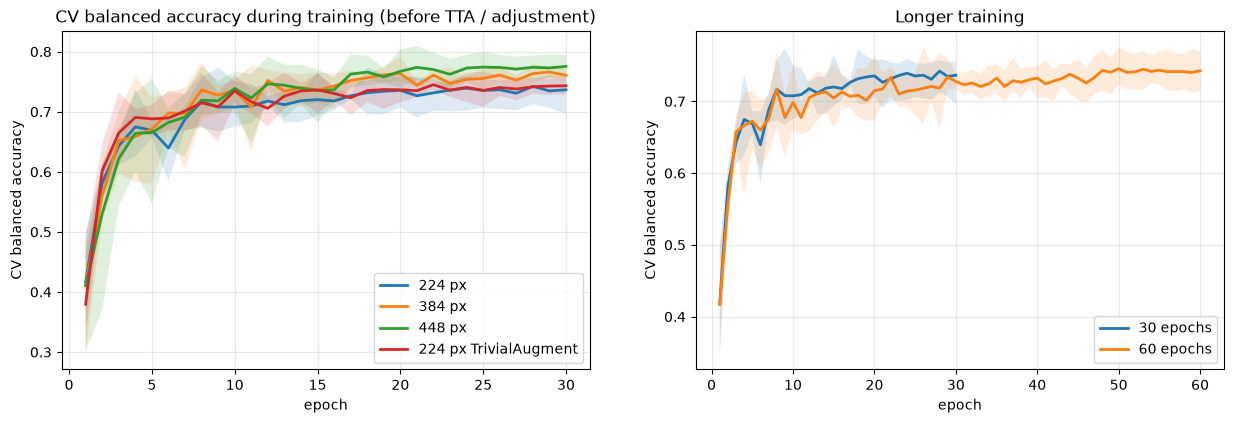

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
A.plot_curves(axes[0], ["resnet50_ce", "resnet50_ce_res384", "resnet50_ce_res448", "resnet50_ce_trivial"],
              ["224 px", "384 px", "448 px", "224 px TrivialAugment"])
axes[0].set_title("CV balanced accuracy during training (before TTA / adjustment)")
A.plot_curves(axes[1], ["resnet50_ce", "resnet50_ce_ep60"], ["30 epochs", "60 epochs"])
axes[1].set_title("Longer training");

## 3. The optimised ResNet-50 on the official test set

,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
plain baseline,0.724 ± 0.012,0.834 ± 0.012,0.740 ± 0.015,0.966 ± 0.002,0.599 ± 0.032,0.953 ± 0.011,0.766,5
baseline + adjustment,0.786 ± 0.013,0.776 ± 0.068,0.695 ± 0.053,0.958 ± 0.006,0.678 ± 0.015,0.912 ± 0.035,0.843,5
optimised ResNet-50,0.835 ± 0.013,0.803 ± 0.020,0.720 ± 0.029,0.973 ± 0.003,0.759 ± 0.032,0.925 ± 0.007,0.87,5
Gessert reproduction,0.770 ± 0.012,0.818 ± 0.009,0.743 ± 0.013,0.965 ± 0.002,0.749 ± 0.014,0.916 ± 0.008,0.787,5


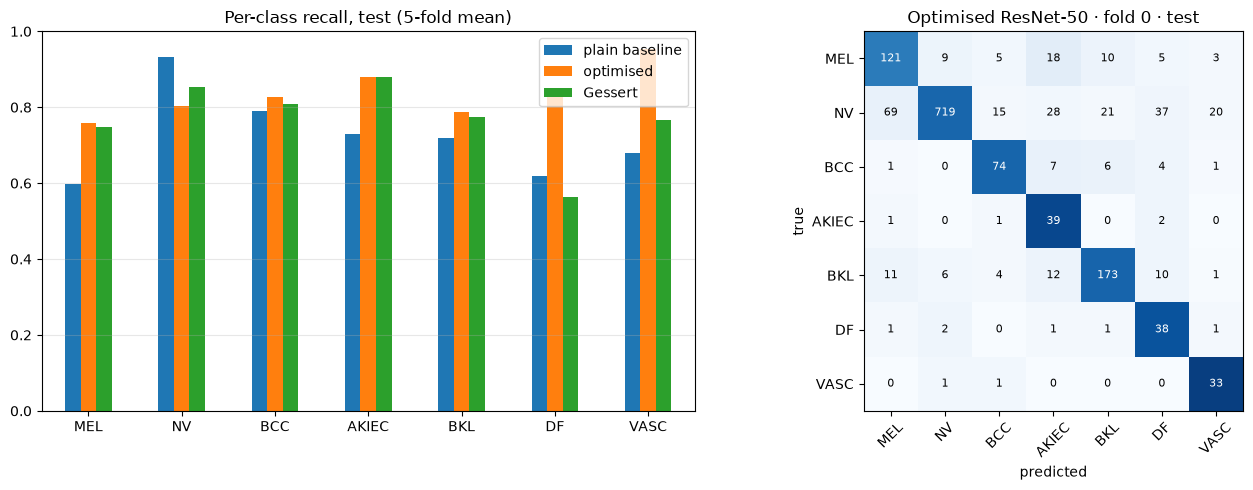

In [6]:
OPT = "resnet50_ce_res448_tta20_la"
display(A.summary(["resnet50_ce", "resnet50_ce_la", OPT, "gessert2018_densenet121"],
                  names=["plain baseline", "baseline + adjustment", "optimised ResNet-50", "Gessert reproduction"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.DataFrame({"plain baseline": A.per_class_recall("resnet50_ce"), "optimised": A.per_class_recall(OPT),
              "Gessert": A.per_class_recall("gessert2018_densenet121")}).plot.bar(ax=axes[0], rot=0)
axes[0].set_ylim(0, 1); axes[0].grid(axis="y", alpha=.3); axes[0].set_title("Per-class recall, test (5-fold mean)")
A.plot_confusion(axes[1], OPT, 0, "Optimised ResNet-50 · fold 0 · test")
plt.tight_layout()

## Takeaways
* **Selected:** ResNet-50, 448 px, plain CE, 20-view TTA, logit adjustment (τ = 1.6) — CV 0.831, **test 0.835 ± 0.014**
  (from 0.724), 5-model average 0.870 (above the paper's 54-model ensemble, 0.856).
* **Resolution is the lever that improves the features:** +0.040 test after adjustment (5/5 folds) and AUC up — unlike
  loss weighting. It also closes the melanoma gap to the Gessert recipe (0.759 vs 0.749 sensitivity).
* TTA adds a little (+0.009 on test, +0.014 on CV). 60 epochs and TrivialAugment did nothing on CV, so they were not kept.
* 384 px gained on CV but not on test — a reminder that differences under ~0.02 are noise at this sample size.